In [1]:
import matplotlib.pyplot as plt
import numpy as np


def plot_selection_result(results, ax, budget=None, label=None, color=None):
    import scipy.stats as sps

    if budget is None:
        budget = results.shape[-1]

    def ci(y):
        br = sps.bootstrap((y,), np.mean, vectorized=True)
        ci_l = br.confidence_interval.low
        ci_u = br.confidence_interval.high
        return ci_l, ci_u

    iters = np.arange(0, budget, 1)
    agg_value = results.mean(axis=0)[:budget].ravel()
    _ci_lb, _ci_ub = ci(results)[:budget]

    line, *_ = ax.plot(iters, agg_value, linewidth=1.5, label=label, color=color)

    ax.plot(iters, _ci_lb, linewidth=1.5, alpha=0.5, color=line.get_color())
    ax.plot(iters, _ci_ub, linewidth=1.5, alpha=0.5, color=line.get_color())
    ax.fill_between(iters, _ci_lb, _ci_ub, alpha=0.3, color=line.get_color())


In [2]:
import torch
import numpy as np


def get_res_p(_path):
    arr = np.loadtxt(_path)
    return get_res_o(arr)

def get_res_o(arr):
    return torch.from_numpy(arr).cummax(axis=-1).values.detach().numpy()

# optuna and random

In [23]:
# get random res

from tidyhebo.optimizers_reference import RealParameter, RealDesignSpace
from botorch.test_functions.synthetic import Hartmann
import torch


problem = Hartmann(dim=6, negate=True)


def get_random(problem):
    params = [
        RealParameter(i, lb, ub) for (i, (lb, ub)) in enumerate(problem.bounds.T.detach().numpy())
    ]
    ds = RealDesignSpace(params)

    # sample initial points
    n_init = 100
    x0 = torch.rand(n_init, len(params)).double()
    x0 = ds.to_domain_space(x0)
    y0 = problem(x0)
    
    return y0

random_out = np.array([get_random(problem) for i in range(30)])

random_res = get_res_o(random_out)


In [24]:
# get optuna res


from botorch.test_functions import Hartmann

problem = Hartmann(dim=6, negate=True)


from tidyhebo.optimizers_reference import OptunaOptimizer, RealParameter, RealDesignSpace


# RealParameter, RealDesignSpace

def get_optuna(problem):
    params = [
        RealParameter(i, lb, ub) for (i, (lb, ub)) in enumerate(problem.bounds.T.detach().numpy())
    ]
    ds = RealDesignSpace(params)

    n_init = 8
    x0 = torch.rand(n_init, len(params)).double()
    x0 = ds.to_domain_space(x0)
    y0 = problem(x0)


    optimizer = OptunaOptimizer(
        parameters=params,
        train_x=x0,
        train_y=y0,
    )

    for i in range(100 - n_init):
        x_new = optimizer.suggest()
        y_new = problem(x_new)
        optimizer.observe(x_new, y_new)
    
    return optimizer.train_y


optuna_out = np.array([get_optuna(problem) for i in range(30)])

optuna_res = get_res_o(optuna_out)

[I 2025-11-08 20:28:45,483] A new study created in memory with name: no-name-c09fb397-4c4c-4e54-bcf4-06a95696e1ae
[I 2025-11-08 20:28:46,157] A new study created in memory with name: no-name-6f3bb102-ab98-433f-b5d8-03ff1670f221
[I 2025-11-08 20:28:46,797] A new study created in memory with name: no-name-61c1df6e-cd36-468a-bf04-48c41ec6c003
[I 2025-11-08 20:28:47,440] A new study created in memory with name: no-name-a86ba1a1-87e5-4f91-a245-99ffd8be2478
[I 2025-11-08 20:28:48,086] A new study created in memory with name: no-name-72c2555a-0382-483a-8879-0f93f491d391
[I 2025-11-08 20:28:48,730] A new study created in memory with name: no-name-6bcfc3ad-5b2d-4601-8463-b62699663053
[I 2025-11-08 20:28:49,381] A new study created in memory with name: no-name-78b37feb-d3c2-4f17-b7c7-471bd292c880
[I 2025-11-08 20:28:49,987] A new study created in memory with name: no-name-47a54106-2614-4d55-91be-4fd0ca341e36
[I 2025-11-08 20:28:50,490] A new study created in memory with name: no-name-28757025-49

In [25]:
np.savetxt("data/random_H6_out.txt", random_out)
np.savetxt("data/optuna_H6_out.txt", optuna_out)

# plotting

In [3]:
import numpy as np
import torch

# random res
random_res = get_res_p("data/random_H6_out.txt")

# optuna 
optuna_res = get_res_p("data/optuna_H6_out.txt")

# hebo
hebo_res = get_res_p("data/vanilla_hebo_res_H6.txt")

# tidyhebo
# tidyhebo_res = get_res_p("data/tidyhebo_H6_out.txt")
tidyhebo_res = get_res_p("tidyhebo_H6_out_2.txt")

# qlogei
qlogei_res = get_res_p("data/qlogei_H6_out.txt")


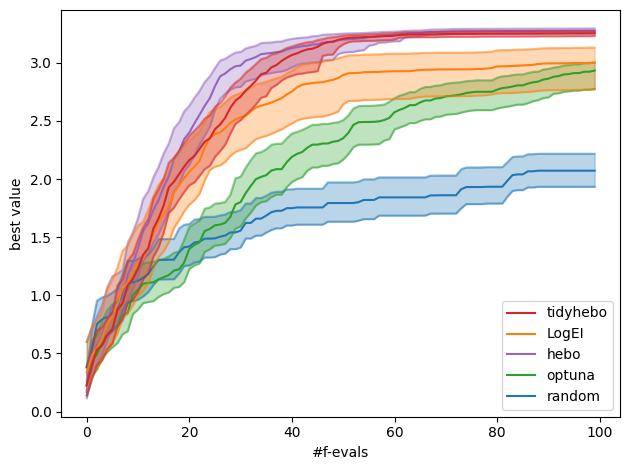

In [6]:
import matplotlib.pyplot as plt

ax = plt.gca()

tr = lambda x: x
# tr = lambda x: np.log10(optimization_got_max - x)

plot_selection_result(random_res, ax, budget=100, label="random", color="tab:blue")
plot_selection_result(optuna_res, ax, budget=100, label="optuna", color="tab:green")
plot_selection_result(hebo_res, ax, budget=100, label="hebo", color="tab:purple")
plot_selection_result(qlogei_res, ax, budget=100, label="LogEI", color="tab:orange")
plot_selection_result(tidyhebo_res, ax, budget=100, label="tidyhebo", color="tab:red")


ax.set_xlabel("#f-evals")
ax.set_ylabel("best value")

ax.figure.tight_layout()

handles, labels = ax.get_legend_handles_labels()
ax.legend(reversed(handles), reversed(labels));